# 🚗 Second-Hand Car Price Prediction & Classification

**Course:** Machine Learning  
**Dataset:** CarDekho Used Cars (302 records, 9 features)  
**Objective:** Predict the selling price (regression) and classify it into Low / Medium / High (classification) using scikit-learn pipelines.

---

## Table of Contents
1. [Unit I – Data Preparation](#unit1)
2. [Unit II – EDA & Feature Engineering](#unit2)
3. [Unit III – Regression Models](#unit3)
4. [Unit IV – Classification Models](#unit4)

In [1]:
# ── Global imports ────────────────────────────────────────────────────────
import sys, os, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

# Make src/ importable from the notebook
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    BrandExtractor, CarAgeFeatureEngineer, NumericCleaner,
    DataFrameImputer, ColumnSelector, iqr_bounds,
    COL_CAR_NAME, COL_YEAR, COL_SELLING, COL_PRESENT,
    COL_KMS, COL_FUEL, COL_SELLER, COL_TRANS, COL_OWNER,
    COL_BRAND, COL_CAR_AGE, COL_KM_PER_YR, CURRENT_YEAR
)

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')
print('sklearn version:', sklearn.__version__)
print('pandas  version:', pd.__version__)
print('numpy   version:', np.__version__)

sklearn version: 1.9.1
pandas  version: 3.1.0
numpy   version: 2.5.4


<a id='unit1'></a>
## UNIT I – Data Preparation

In this unit we:
- Load the raw CSV and inspect it
- Convert any string-encoded numbers (e.g. `'19.7 kmpl'`) to floats
- Handle missing values (median for numeric, mode for categorical)
- Encode categorical variables
- Scale numeric features
- Split into 80/20 train-test sets

In [2]:
# ── 1.1  Load Data ────────────────────────────────────────────────────────
DATA_PATH = PROJECT_ROOT / 'data' / 'car_data.csv'
df_raw = pd.read_csv(DATA_PATH)
print(f'Shape: {df_raw.shape}')
df_raw.head()

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# ── 1.2  Info & Describe ──────────────────────────────────────────────────
print('\n--- dtypes ---')
print(df_raw.dtypes)
print('\n--- missing values ---')
print(df_raw.isnull().sum())
df_raw.describe(include='all')


--- dtypes ---
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

--- missing values ---
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


In [4]:
# ── 1.3  Clean numeric columns (strip units if present) ───────────────────
df = df_raw.copy()
numeric_cols = [COL_YEAR, COL_SELLING, COL_PRESENT, COL_KMS, COL_OWNER]
for c in numeric_cols:
    df[c] = pd.to_numeric(
        df[c].astype(str).str.extract(r'([\d.]+)', expand=False),
        errors='coerce'
    )

# ── 1.4  Handle missing values ────────────────────────────────────────────
for c in [COL_YEAR, COL_PRESENT, COL_KMS, COL_OWNER]:
    df[c] = df[c].fillna(df[c].median())
for c in [COL_FUEL, COL_SELLER, COL_TRANS]:
    df[c] = df[c].fillna(df[c].mode()[0])
df = df.dropna(subset=[COL_SELLING])

print('Missing after cleaning:')
print(df.isnull().sum())
print(f'\nShape after cleaning: {df.shape}')

Missing after cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Shape after cleaning: (301, 9)


In [5]:
# ── 1.5  Encode categoricals (for standalone analysis; pipeline does this) ─
from sklearn.preprocessing import LabelEncoder

df_enc = df.copy()
le = LabelEncoder()
for c in [COL_FUEL, COL_SELLER, COL_TRANS]:
    df_enc[c + '_enc'] = le.fit_transform(df_enc[c].astype(str))

# ── 1.6  Feature Engineering for EDA ──────────────────────────────────────
df_enc[COL_BRAND]     = df_enc[COL_CAR_NAME].str.strip().str.split().str[0].str.lower().str.capitalize()
df_enc[COL_CAR_AGE]   = (CURRENT_YEAR - df_enc[COL_YEAR]).clip(lower=0)
df_enc[COL_KM_PER_YR] = df_enc[COL_KMS] / df_enc[COL_CAR_AGE].replace(0, 1)

print('Encoded + Feature engineered columns:')
df_enc.head(3)

Encoded + Feature engineered columns:


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Fuel_Type_enc,Seller_Type_enc,Transmission_enc,Brand,Car_Age,Km_Per_Year
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,2,0,1,Ritz,10,2700.000000
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,1,0,1,Sx4,11,3909.090909
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,2,0,1,Ciaz,7,985.714286


In [6]:
# ── 1.7  Scale numeric features (preview) ─────────────────────────────────
from sklearn.preprocessing import StandardScaler

num_preview_cols = [COL_YEAR, COL_PRESENT, COL_KMS, COL_OWNER, COL_CAR_AGE, COL_KM_PER_YR]
scaler_preview = StandardScaler()
scaled_preview = scaler_preview.fit_transform(df_enc[num_preview_cols])
print('Scaled feature stats (mean≈0, std≈1):')
pd.DataFrame(scaled_preview, columns=num_preview_cols).describe().round(3)

Scaled feature stats (mean≈0, std≈1):


,Year,Present_Price,Kms_Driven,Owner,Car_Age,Km_Per_Year
count,301.000,301.000,301.000,301.000,301.000,301.000
mean,-0.000,-0.000,0.000,0.000,-0.000,-0.000
std,1.002,1.002,1.002,1.002,1.002,1.002
min,-3.682,-0.847,-0.939,-0.175,-1.515,-1.249
25%,-0.564,-0.745,-0.565,-0.175,-0.822,-0.641
50%,0.129,-0.142,-0.127,-0.175,-0.129,-0.124
75%,0.822,0.263,0.304,-0.175,0.564,0.429
max,1.515,9.846,11.928,11.947,3.682,10.689


In [7]:
# ── 1.8  Train-Test Split ─────────────────────────────────────────────────
from sklearn.model_selection import train_test_split

FEATURE_COLS = [COL_CAR_NAME, COL_YEAR, COL_PRESENT, COL_KMS, COL_FUEL, COL_SELLER, COL_TRANS, COL_OWNER]
X_raw = df[FEATURE_COLS].copy()
y     = df[COL_SELLING].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train: {X_train_raw.shape}, Test: {X_test_raw.shape}')

Train: (240, 8), Test: (61, 8)


<a id='unit2'></a>
## UNIT II – EDA & Feature Engineering

We explore:
- Price distribution (raw and log-transformed)
- Price vs Year and Kms Driven (scatter plots)
- Average price by Brand, Fuel type and Transmission
- Correlation heatmap
- IQR-based outlier detection and removal
- New engineered features: `Car_Age`, `Km_Per_Year`
- Feature importance using Random Forest
- Class imbalance check for the price categories

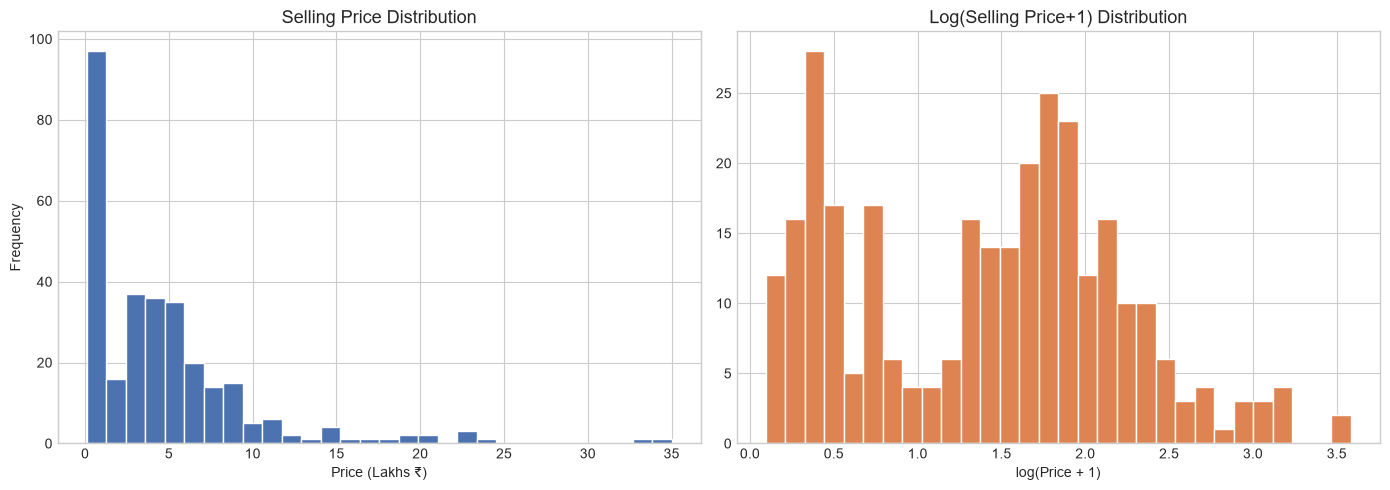

In [8]:
# ── 2.1  Price Distribution ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_enc[COL_SELLING], bins=30, color='#4C72B0', edgecolor='white')
axes[0].set_title('Selling Price Distribution', fontsize=13)
axes[0].set_xlabel('Price (Lakhs ₹)')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(df_enc[COL_SELLING]), bins=30, color='#DD8452', edgecolor='white')
axes[1].set_title('Log(Selling Price+1) Distribution', fontsize=13)
axes[1].set_xlabel('log(Price + 1)')
plt.tight_layout(); plt.show()

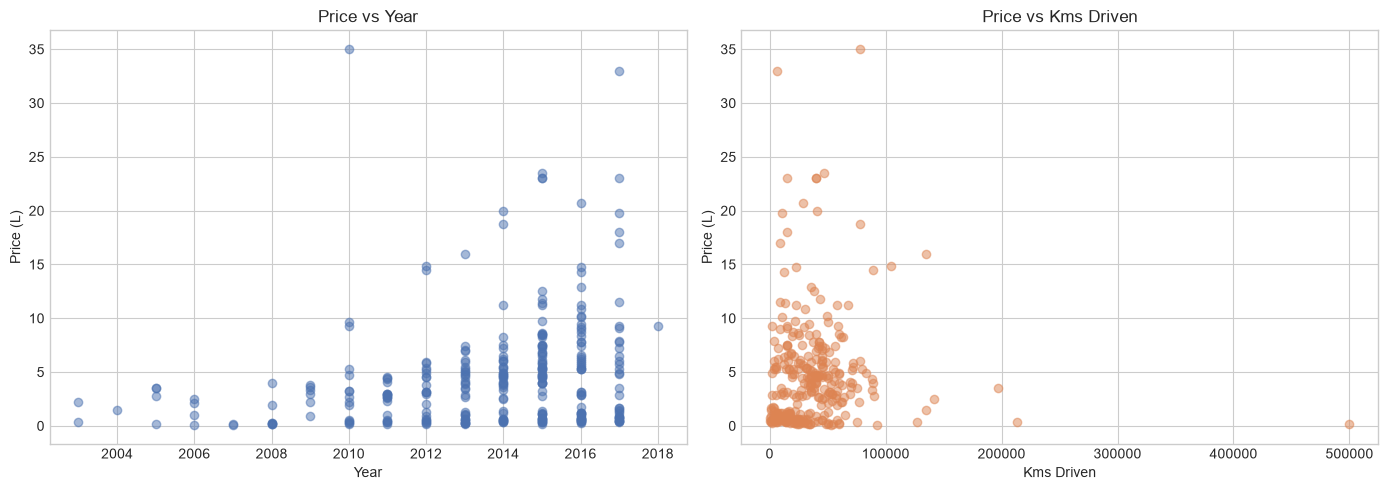

In [9]:
# ── 2.2  Price vs Year and Kms Driven ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(df_enc[COL_YEAR], df_enc[COL_SELLING], alpha=0.5, color='#4C72B0')
axes[0].set_title('Price vs Year'); axes[0].set_xlabel('Year'); axes[0].set_ylabel('Price (L)')

axes[1].scatter(df_enc[COL_KMS], df_enc[COL_SELLING], alpha=0.5, color='#DD8452')
axes[1].set_title('Price vs Kms Driven'); axes[1].set_xlabel('Kms Driven'); axes[1].set_ylabel('Price (L)')
plt.tight_layout(); plt.show()

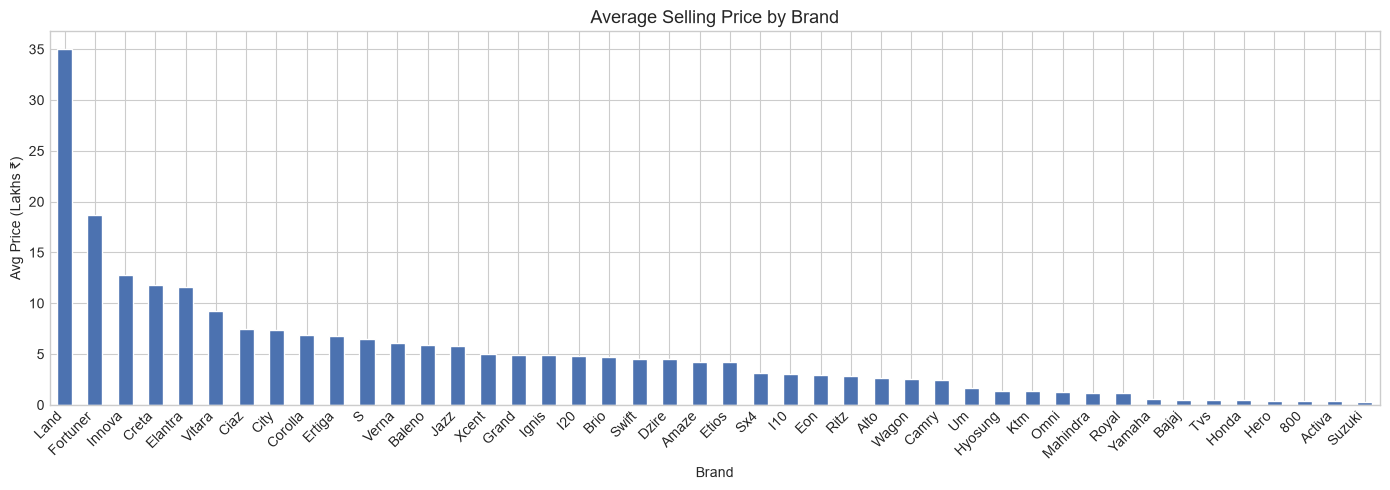

In [10]:
# ── 2.3  Average Price by Brand ───────────────────────────────────────────
brand_price = df_enc.groupby(COL_BRAND)[COL_SELLING].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 5))
brand_price.plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='white')
ax.set_title('Average Selling Price by Brand', fontsize=13)
ax.set_ylabel('Avg Price (Lakhs ₹)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

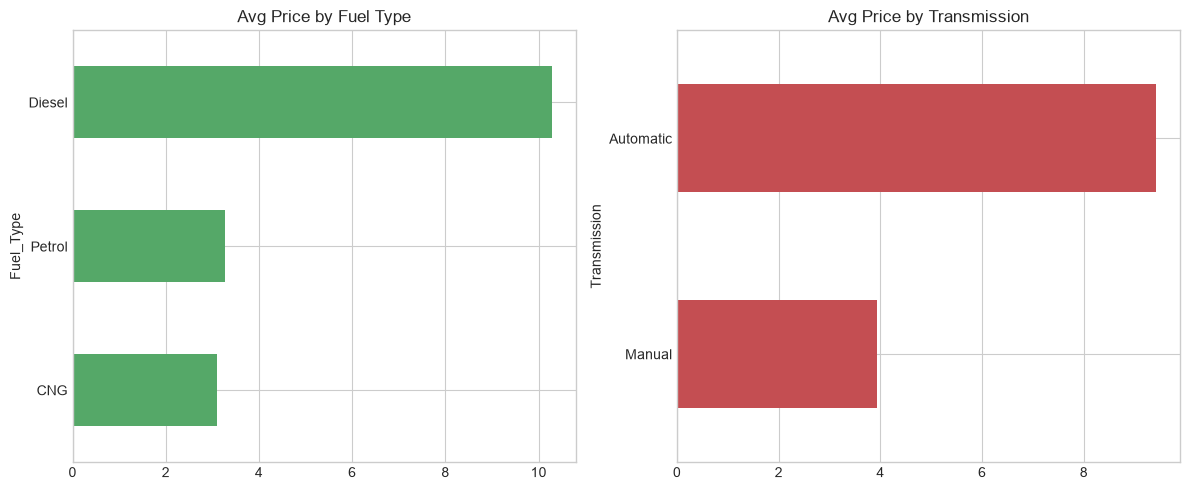

In [11]:
# ── 2.4  Average Price by Fuel & Transmission ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df_enc.groupby(COL_FUEL)[COL_SELLING].mean().sort_values().plot(
    kind='barh', ax=axes[0], color='#55A868')
axes[0].set_title('Avg Price by Fuel Type')

df_enc.groupby(COL_TRANS)[COL_SELLING].mean().sort_values().plot(
    kind='barh', ax=axes[1], color='#C44E52')
axes[1].set_title('Avg Price by Transmission')
plt.tight_layout(); plt.show()

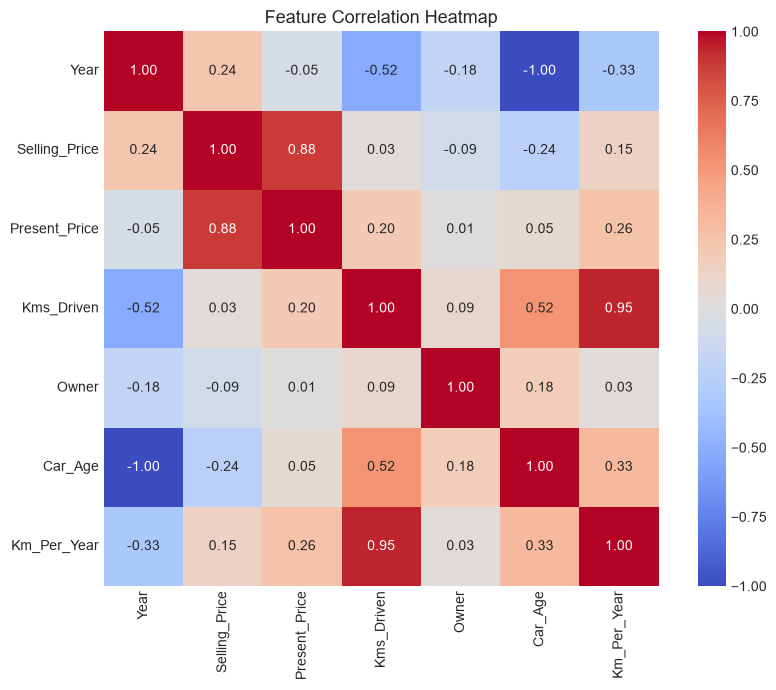


Top correlations with Selling_Price:
Selling_Price    1.000000
Present_Price    0.878983
Year             0.236141
Km_Per_Year      0.145080
Kms_Driven       0.029187
Owner           -0.088344
Car_Age         -0.236141
Name: Selling_Price, dtype: float64


In [12]:
# ── 2.5  Correlation Heatmap ──────────────────────────────────────────────
num_cols = [COL_YEAR, COL_SELLING, COL_PRESENT, COL_KMS, COL_OWNER, COL_CAR_AGE, COL_KM_PER_YR]
corr = df_enc[num_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax, square=True)
ax.set_title('Feature Correlation Heatmap', fontsize=13)
plt.tight_layout(); plt.show()

print('\nTop correlations with Selling_Price:')
print(corr[COL_SELLING].sort_values(ascending=False))

In [13]:
# ── 2.6  IQR Outlier Detection & Handling ────────────────────────────────
df_clean = df_enc.copy()
before = len(df_clean)

for col in [COL_SELLING, COL_KMS, COL_PRESENT]:
    lo, hi = iqr_bounds(df_clean[col])
    n_out = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    print(f'{col}: {n_out} outliers (bounds [{lo:.2f}, {hi:.2f}])')
    df_clean = df_clean[(df_clean[col] >= lo) & (df_clean[col] <= hi)]

print(f'\nRows before: {before}, after IQR filter: {len(df_clean)}')

Selling_Price: 17 outliers (bounds [-6.75, 13.65])
Kms_Driven: 6 outliers (bounds [-34785.75, 97978.25])
Present_Price: 2 outliers (bounds [-11.59, 21.99])

Rows before: 301, after IQR filter: 276


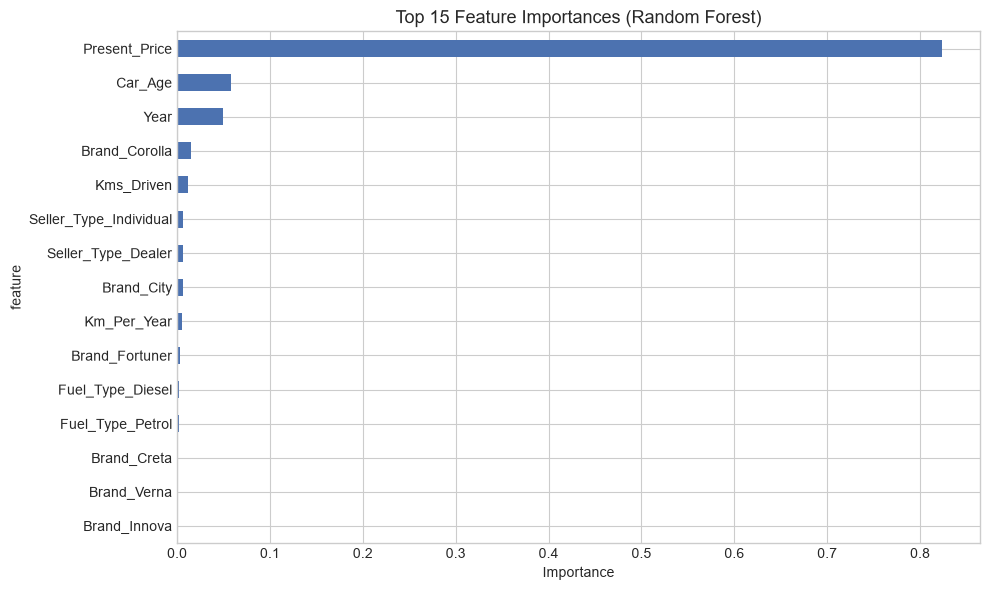

In [14]:
# ── 2.7  Feature Importance with Random Forest ────────────────────────────
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

num_feats = [COL_YEAR, COL_PRESENT, COL_KMS, COL_OWNER, COL_CAR_AGE, COL_KM_PER_YR]
cat_feats = [COL_BRAND, COL_FUEL, COL_SELLER, COL_TRANS]

ct = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median'))]), num_feats),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_feats),
])

X_fi = df_clean[[COL_CAR_NAME, COL_YEAR, COL_PRESENT, COL_KMS, COL_FUEL, COL_SELLER, COL_TRANS, COL_OWNER]].copy()
y_fi = df_clean[COL_SELLING].values

fi_pipe = Pipeline([
    ('brand', BrandExtractor()),
    ('age',   CarAgeFeatureEngineer()),
    ('prep',  ct),
    ('rfr',   RandomForestRegressor(n_estimators=100, max_depth=10, random_state=RANDOM_STATE)),
])
fi_pipe.fit(X_fi, y_fi)

# Get feature names
ohe_names = list(fi_pipe.named_steps['prep'].named_transformers_['cat']['ohe']
                 .get_feature_names_out(cat_feats))
all_names = num_feats + ohe_names
importances = fi_pipe.named_steps['rfr'].feature_importances_

fi_df = pd.DataFrame({'feature': all_names, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
fi_df.plot(kind='barh', x='feature', y='importance', ax=ax, color='#4C72B0', legend=False)
ax.set_title('Top 15 Feature Importances (Random Forest)', fontsize=13)
ax.set_xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

Class distribution:
price_category
Low       92
Medium    92
High      92
Name: count, dtype: int64


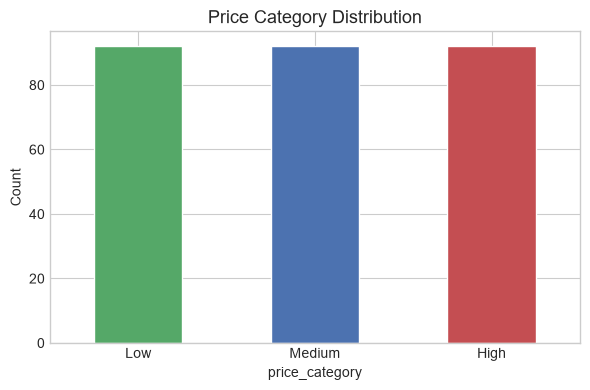

In [15]:
# ── 2.8  Price Category & Class Imbalance Check ───────────────────────────
df_clean = df_clean.copy()
df_clean['price_category'] = pd.qcut(
    df_clean[COL_SELLING], q=3, labels=['Low', 'Medium', 'High']
)

cat_counts = df_clean['price_category'].value_counts()
print('Class distribution:')
print(cat_counts)

fig, ax = plt.subplots(figsize=(6, 4))
cat_counts.plot(kind='bar', ax=ax, color=['#55A868', '#4C72B0', '#C44E52'], edgecolor='white')
ax.set_title('Price Category Distribution', fontsize=13)
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

<a id='unit3'></a>
## UNIT III – Regression Models

We build and compare the following regression models, all wrapped inside a scikit-learn `Pipeline`:
1. Simple Linear Regression
2. Multiple Linear Regression
3. Polynomial Regression (degree 2)
4. Ridge Regression (best α via cross-validation)
5. Lasso Regression (best α via cross-validation)
6. Elastic Net
7. Random Forest Regressor (≤100 trees)

**Metrics:** MAE, MSE, RMSE, R²

In [16]:
# ── 3.0  Pipeline building blocks ────────────────────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NUM_FEATURES = [COL_YEAR, COL_PRESENT, COL_KMS, COL_OWNER, COL_CAR_AGE, COL_KM_PER_YR]
CAT_FEATURES = [COL_BRAND, COL_FUEL, COL_SELLER, COL_TRANS]

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, NUM_FEATURES),
    ('cat', categorical_transformer, CAT_FEATURES),
], remainder='drop')

def make_pipeline(model):
    return Pipeline([
        ('brand', BrandExtractor()),
        ('age',   CarAgeFeatureEngineer()),
        ('prep',  preprocessor),
        ('model', model),
    ])

FEATURE_COLS = [COL_CAR_NAME, COL_YEAR, COL_PRESENT, COL_KMS, COL_FUEL, COL_SELLER, COL_TRANS, COL_OWNER]
X = df_clean[FEATURE_COLS].copy()
y_reg = df_clean[COL_SELLING].values
y_clf = df_clean['price_category'].values

X_train, X_test, yr_train, yr_test = train_test_split(X, y_reg, test_size=0.2, random_state=RANDOM_STATE)
_, _, yc_train, yc_test = train_test_split(X, y_clf, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}  Test: {X_test.shape}')

Train: (220, 8)  Test: (56, 8)


In [17]:
# ── 3.1  Evaluation helper ────────────────────────────────────────────────
reg_results = []

def eval_reg(name, pipe, Xtr=X_train, ytr=yr_train, Xte=X_test, yte=yr_test, verbose=True):
    pipe.fit(Xtr, ytr)
    yp = pipe.predict(Xte)
    mae  = mean_absolute_error(yte, yp)
    mse  = mean_squared_error(yte, yp)
    rmse = np.sqrt(mse)
    r2   = r2_score(yte, yp)
    cv   = cross_val_score(pipe, Xtr, ytr, cv=5, scoring='r2').mean()
    if verbose:
        print(f'{name:30s}  MAE={mae:.3f}  RMSE={rmse:.3f}  R²={r2:.3f}  CV-R²={cv:.3f}')
    reg_results.append({'Model': name, 'MAE': round(mae,4), 'MSE': round(mse,4),
                        'RMSE': round(rmse,4), 'R²': round(r2,4), 'CV_R²': round(cv,4)})
    return pipe, yp

In [18]:
# ── 3.2  Simple Linear Regression ────────────────────────────────────────
print('--- Simple Linear Regression (single feature: Present_Price) ---')
simple_lr = Pipeline([
    ('brand', BrandExtractor()),
    ('age',   CarAgeFeatureEngineer()),
    ('prep',  ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), [COL_PRESENT]),
    ], remainder='drop')),
    ('model', LinearRegression()),
])
pipe_slr, yp_slr = eval_reg('Simple Linear (Present_Price)', simple_lr)

--- Simple Linear Regression (single feature: Present_Price) ---
Simple Linear (Present_Price)   MAE=1.019  RMSE=1.465  R²=0.752  CV-R²=0.735


In [19]:
# ── 3.3  Multiple Linear Regression ──────────────────────────────────────
print('--- Multiple Linear Regression ---')
pipe_mlr, yp_mlr = eval_reg('Multiple Linear', make_pipeline(LinearRegression()))

--- Multiple Linear Regression ---


Multiple Linear                 MAE=0.764  RMSE=1.090  R²=0.863  CV-R²=0.915


In [20]:
# ── 3.4  Polynomial Regression (degree 2) ────────────────────────────────
print('--- Polynomial Regression (degree=2) ---')
poly_pipe = Pipeline([
    ('brand', BrandExtractor()),
    ('age',   CarAgeFeatureEngineer()),
    ('prep',  preprocessor),
    ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression()),
])
pipe_poly, yp_poly = eval_reg('Polynomial (deg=2)', poly_pipe)

--- Polynomial Regression (degree=2) ---


Polynomial (deg=2)              MAE=1.592  RMSE=2.982  R²=-0.028  CV-R²=-80.523


In [21]:
# ── 3.5  Ridge with cross-validated alpha ─────────────────────────────────
print('--- Ridge Regression (alpha search) ---')
alphas = [0.01, 0.1, 1, 10, 100]
best_a, best_s = None, -999
for a in alphas:
    s = cross_val_score(make_pipeline(Ridge(alpha=a, random_state=RANDOM_STATE)),
                        X_train, yr_train, cv=5, scoring='r2').mean()
    print(f'  alpha={a:6.2f}  CV-R²={s:.4f}')
    if s > best_s: best_s = s; best_a = a
print(f'Best alpha: {best_a}')
pipe_ridge, yp_ridge = eval_reg(f'Ridge (α={best_a})',
                                 make_pipeline(Ridge(alpha=best_a, random_state=RANDOM_STATE)))

--- Ridge Regression (alpha search) ---
  alpha=  0.01  CV-R²=0.9167


  alpha=  0.10  CV-R²=0.9247
  alpha=  1.00  CV-R²=0.9306
  alpha= 10.00  CV-R²=0.9001


  alpha=100.00  CV-R²=0.7966
Best alpha: 1
Ridge (α=1)                     MAE=0.759  RMSE=1.050  R²=0.872  CV-R²=0.931


In [22]:
# ── 3.6  Lasso with cross-validated alpha ─────────────────────────────────
print('--- Lasso Regression (alpha search) ---')
best_a_l, best_s_l = None, -999
for a in alphas:
    s = cross_val_score(make_pipeline(Lasso(alpha=a, random_state=RANDOM_STATE, max_iter=5000)),
                        X_train, yr_train, cv=5, scoring='r2').mean()
    print(f'  alpha={a:6.2f}  CV-R²={s:.4f}')
    if s > best_s_l: best_s_l = s; best_a_l = a
print(f'Best alpha: {best_a_l}')
pipe_lasso, yp_lasso = eval_reg(f'Lasso (α={best_a_l})',
                                 make_pipeline(Lasso(alpha=best_a_l, random_state=RANDOM_STATE, max_iter=5000)))

--- Lasso Regression (alpha search) ---


  alpha=  0.01  CV-R²=0.9251


  alpha=  0.10  CV-R²=0.8624
  alpha=  1.00  CV-R²=0.6319


  alpha= 10.00  CV-R²=-0.0119


  alpha=100.00  CV-R²=-0.0119
Best alpha: 0.01
Lasso (α=0.01)                  MAE=0.768  RMSE=1.048  R²=0.873  CV-R²=0.925


In [23]:
# ── 3.7  ElasticNet ───────────────────────────────────────────────────────
print('--- ElasticNet ---')
pipe_en, yp_en = eval_reg('ElasticNet',
    make_pipeline(ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=5000)))

--- ElasticNet ---


ElasticNet                      MAE=0.850  RMSE=1.079  R²=0.865  CV-R²=0.873


In [24]:
# ── 3.8  Random Forest Regressor ─────────────────────────────────────────
print('--- Random Forest Regressor ---')
pipe_rfr, yp_rfr = eval_reg('Random Forest Reg',
    make_pipeline(RandomForestRegressor(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)))

--- Random Forest Regressor ---


Random Forest Reg               MAE=0.445  RMSE=0.870  R²=0.912  CV-R²=0.946


In [25]:
# ── 3.9  Regression Comparison Table ─────────────────────────────────────
reg_df = pd.DataFrame(reg_results)
display(reg_df.style
        .highlight_max(subset=['R²', 'CV_R²'], color='#d4edda')
        .highlight_min(subset=['MAE', 'RMSE'], color='#d4edda')
        .format(precision=4)
       )

,Model,MAE,MSE,RMSE,R²,CV_R²
0,Simple Linear (Present_Price),1.0190,2.1457,1.4648,0.7519,0.7351
1,Multiple Linear,0.7638,1.1882,1.0900,0.8626,0.9147
2,Polynomial (deg=2),1.5923,8.8945,2.9824,-0.0285,-80.5232
3,Ridge (α=1),0.7586,1.1031,1.0503,0.8724,0.9306
4,Lasso (α=0.01),0.7677,1.0990,1.0483,0.8729,0.9251
5,ElasticNet,0.8504,1.1653,1.0795,0.8653,0.8732
6,Random Forest Reg,0.4452,0.7570,0.8701,0.9125,0.9464


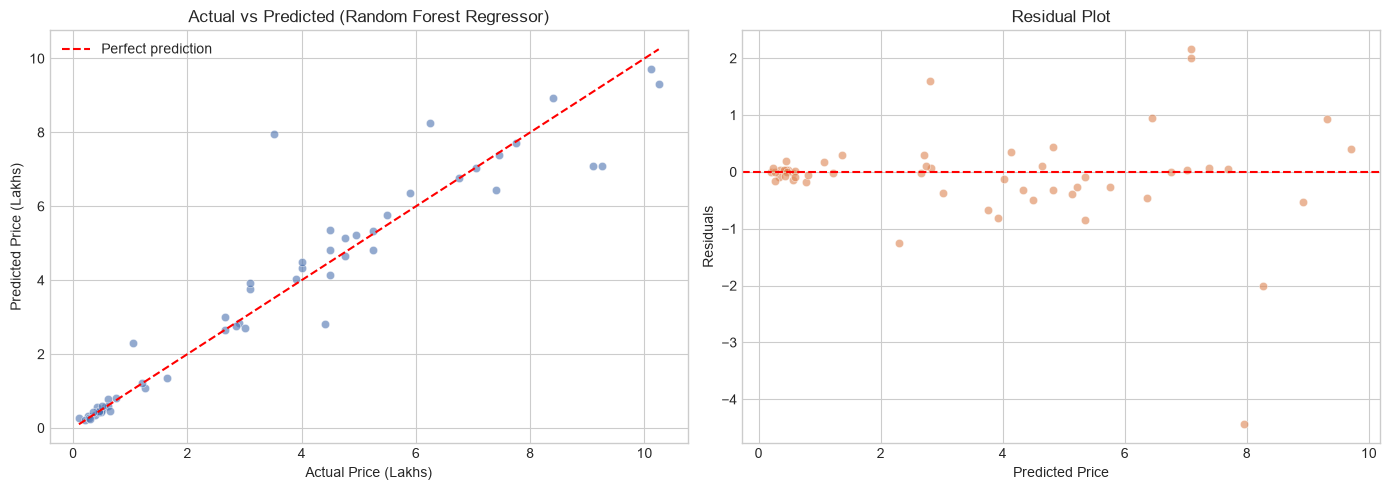

In [26]:
# ── 3.10  Actual vs Predicted & Residuals (best model) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Use RF predictions
axes[0].scatter(yr_test, yp_rfr, alpha=0.6, color='#4C72B0', edgecolors='white', linewidth=0.5)
lims = [min(yr_test.min(), yp_rfr.min()), max(yr_test.max(), yp_rfr.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual Price (Lakhs)'); axes[0].set_ylabel('Predicted Price (Lakhs)')
axes[0].set_title('Actual vs Predicted (Random Forest Regressor)', fontsize=12)
axes[0].legend()

residuals = yr_test - yp_rfr
axes[1].scatter(yp_rfr, residuals, alpha=0.6, color='#DD8452', edgecolors='white', linewidth=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Price'); axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot', fontsize=12)

plt.tight_layout(); plt.show()

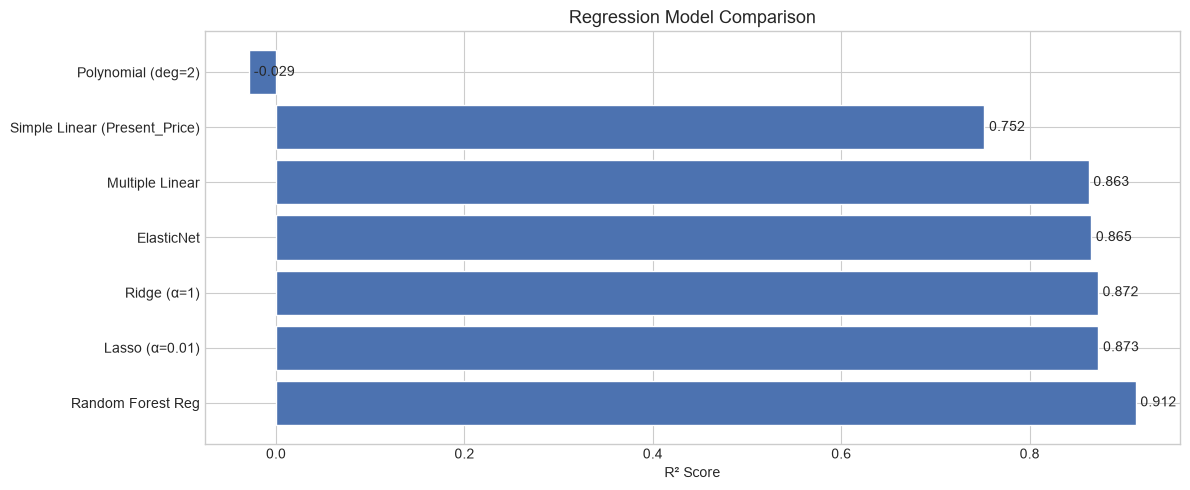

In [27]:
# ── 3.11  Regression Model Comparison Bar Chart ────────────────────────────
reg_sorted = reg_df.sort_values('R²', ascending=False)
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(reg_sorted['Model'], reg_sorted['R²'], color='#4C72B0', edgecolor='white')
for bar, val in zip(bars, reg_sorted['R²']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=10)
ax.set_xlabel('R² Score')
ax.set_title('Regression Model Comparison', fontsize=13)
plt.tight_layout(); plt.show()

In [28]:
# ── 3.12  Save best regressor ─────────────────────────────────────────────
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(pipe_rfr, MODELS_DIR / 'regressor.joblib', compress=3)
print(f"Saved regressor.joblib ({(MODELS_DIR/'regressor.joblib').stat().st_size/1024:.1f} KB)")

Saved regressor.joblib (371.3 KB)


<a id='unit4'></a>
## UNIT IV – Classification Models

We create a `price_category` column using `pd.qcut` and train six classifiers:
1. Logistic Regression
2. K-Nearest Neighbours (KNN)
3. Decision Tree
4. Random Forest
5. Support Vector Machine (SVM, RBF kernel)
6. Gaussian Naïve Bayes

**Metrics:** Accuracy, Macro Precision / Recall / F1, One-vs-Rest ROC-AUC  
**Plots:** Confusion matrix, ROC curves

In [29]:
# ── 4.0  Imports ──────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize

LABELS = ['Low', 'Medium', 'High']
clf_results = []

def eval_clf(name, pipe, Xtr=X_train, ytr=yc_train, Xte=X_test, yte=yc_test):
    pipe.fit(Xtr, ytr)
    yp = pipe.predict(Xte)
    acc = accuracy_score(yte, yp)
    rpt = classification_report(yte, yp, output_dict=True, zero_division=0)
    mp  = rpt['macro avg']['precision']
    mr  = rpt['macro avg']['recall']
    mf1 = rpt['macro avg']['f1-score']
    try:
        if hasattr(pipe, 'predict_proba'):
            yprob = pipe.predict_proba(Xte)
            ybin  = label_binarize(yte, classes=pipe.classes_)
            auc   = roc_auc_score(ybin, yprob, multi_class='ovr', average='macro')
        else:
            auc   = float('nan')
    except Exception:
        auc = float('nan')
    print(f'{name:28s}  Acc={acc:.3f}  P={mp:.3f}  R={mr:.3f}  F1={mf1:.3f}  AUC={auc:.3f}')
    clf_results.append({
        'Model': name, 'Accuracy': round(acc,4),
        'Macro_Precision': round(mp,4), 'Macro_Recall': round(mr,4),
        'Macro_F1': round(mf1,4), 'ROC_AUC': round(auc,4) if not np.isnan(auc) else None
    })
    return pipe

In [30]:
# ── 4.1  Train all classifiers ────────────────────────────────────────────
pipe_lr  = eval_clf('Logistic Regression',   make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))
pipe_knn = eval_clf('KNN (k=5)',              make_pipeline(KNeighborsClassifier(n_neighbors=5)))
pipe_dt  = eval_clf('Decision Tree',          make_pipeline(DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)))
pipe_rfc = eval_clf('Random Forest Clf',      make_pipeline(RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)))
pipe_svm = eval_clf('SVM (RBF)',              make_pipeline(SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)))
pipe_gnb = eval_clf('Gaussian NB',            make_pipeline(GaussianNB()))

Logistic Regression           Acc=0.875  P=0.879  R=0.869  F1=0.872  AUC=0.969
KNN (k=5)                     Acc=0.839  P=0.841  R=0.837  F1=0.834  AUC=0.951
Decision Tree                 Acc=0.911  P=0.908  R=0.911  F1=0.909  AUC=0.933


Random Forest Clf             Acc=0.857  P=0.852  R=0.855  F1=0.852  AUC=0.960
SVM (RBF)                     Acc=0.857  P=0.855  R=0.851  F1=0.853  AUC=0.953
Gaussian NB                   Acc=0.768  P=0.778  R=0.770  F1=0.744  AUC=0.900


In [31]:
# ── 4.2  Classification Comparison Table ──────────────────────────────────
clf_df = pd.DataFrame(clf_results)
display(clf_df.style
        .highlight_max(subset=['Accuracy', 'Macro_F1'], color='#d4edda')
        .format(precision=4)
       )

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,ROC_AUC
0,Logistic Regression,0.8750,0.8792,0.8690,0.8725,0.9685
1,KNN (k=5),0.8393,0.8412,0.8372,0.8340,0.9513
2,Decision Tree,0.9107,0.9079,0.9107,0.9088,0.9332
3,Random Forest Clf,0.8571,0.8520,0.8547,0.8522,0.9598
4,SVM (RBF),0.8571,0.8551,0.8515,0.8528,0.9528
5,Gaussian NB,0.7679,0.7780,0.7703,0.7440,0.8995


In [32]:
# ── 4.3  Detailed Classification Report (best model) ──────────────────────
# Identify best classifier by Macro_F1
best_idx  = clf_df['Macro_F1'].idxmax()
best_name = clf_df.loc[best_idx, 'Model']
all_pipes = [pipe_lr, pipe_knn, pipe_dt, pipe_rfc, pipe_svm, pipe_gnb]
best_pipe = all_pipes[best_idx]
print(f'Best classifier: {best_name}')
print(classification_report(yc_test, best_pipe.predict(X_test), target_names=LABELS, zero_division=0))

Best classifier: Decision Tree
              precision    recall  f1-score   support

         Low       0.88      0.94      0.91        16
      Medium       0.95      0.95      0.95        21
        High       0.89      0.84      0.86        19

    accuracy                           0.91        56
   macro avg       0.91      0.91      0.91        56
weighted avg       0.91      0.91      0.91        56



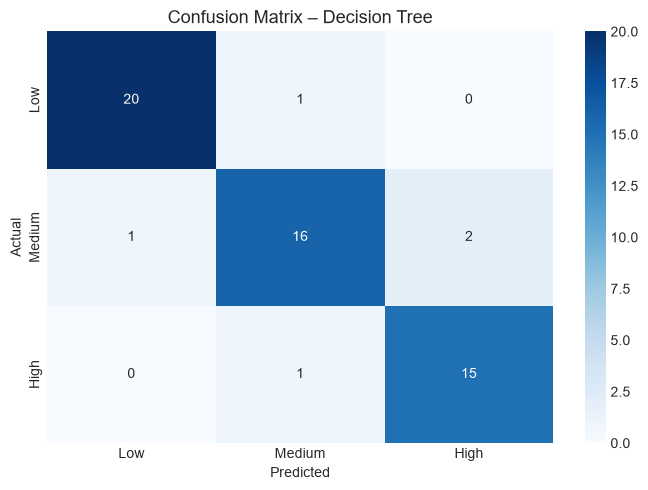

In [33]:
# ── 4.4  Confusion Matrix ─────────────────────────────────────────────────
cm = confusion_matrix(yc_test, best_pipe.predict(X_test), labels=LABELS)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set_title(f'Confusion Matrix – {best_name}', fontsize=13)
ax.set_ylabel('Actual'); ax.set_xlabel('Predicted')
plt.tight_layout(); plt.show()

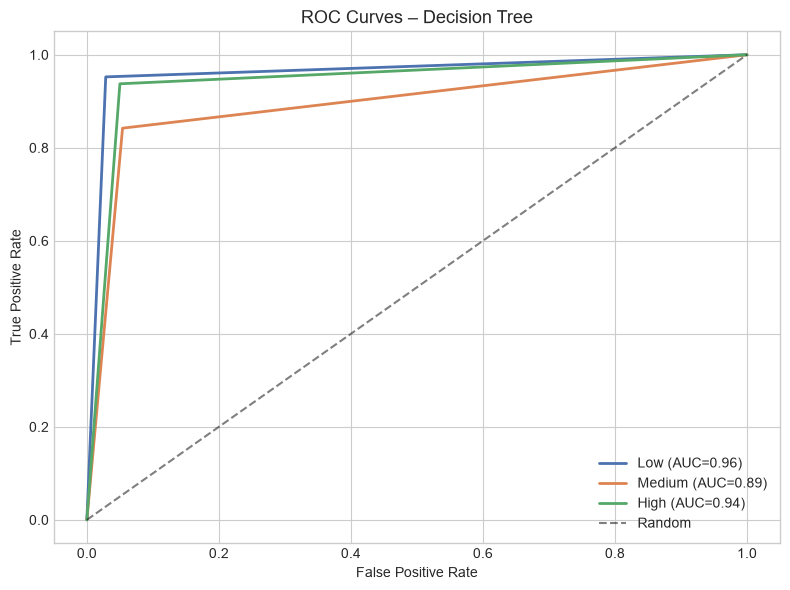

In [34]:
# ── 4.5  ROC Curves (One-vs-Rest) ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
color_map = {'Low': '#4C72B0', 'Medium': '#DD8452', 'High': '#55A868'}
clf_classes = list(best_pipe.classes_)
for label in LABELS:
    try:
        if hasattr(best_pipe, 'predict_proba') and label in clf_classes:
            col_idx = clf_classes.index(label)
            yprob_col = best_pipe.predict_proba(X_test)[:, col_idx]
            y_true_binary = (np.array(yc_test) == label).astype(int)
            fpr, tpr, _ = roc_curve(y_true_binary, yprob_col)
            auc_val = roc_auc_score(y_true_binary, yprob_col)
            ax.plot(fpr, tpr, color=color_map.get(label, '#333333'), lw=2, label=f'{label} (AUC={auc_val:.2f})')
    except Exception as e:
        print(f'Skipping {label}: {e}')
ax.plot([0,1],[0,1], 'k--', alpha=0.5, label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC Curves – {best_name}', fontsize=13)
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

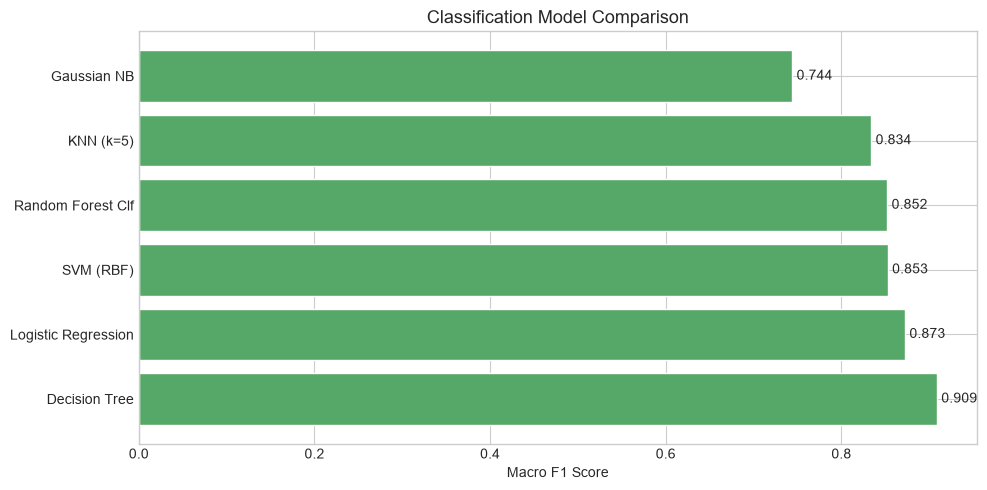

In [35]:
# ── 4.6  Classification Comparison Bar Chart ──────────────────────────────
clf_sorted = clf_df.sort_values('Macro_F1', ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(clf_sorted['Model'], clf_sorted['Macro_F1'], color='#55A868', edgecolor='white')
for bar, val in zip(bars, clf_sorted['Macro_F1']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=10)
ax.set_xlabel('Macro F1 Score')
ax.set_title('Classification Model Comparison', fontsize=13)
plt.tight_layout(); plt.show()

In [36]:
# ── 4.7  Save best classifier and metadata.json ───────────────────────────
joblib.dump(best_pipe, MODELS_DIR / 'classifier.joblib', compress=3)
print(f"Saved classifier.joblib ({(MODELS_DIR/'classifier.joblib').stat().st_size/1024:.1f} KB)")

# Collect metadata
q33 = float(df_clean[COL_SELLING].quantile(1/3))
q67 = float(df_clean[COL_SELLING].quantile(2/3))

brands_list  = sorted(df_clean[COL_BRAND].dropna().unique().tolist())
fuels_list   = sorted(df_clean[COL_FUEL].dropna().unique().tolist())
sellers_list = sorted(df_clean[COL_SELLER].dropna().unique().tolist())
trans_list   = sorted(df_clean[COL_TRANS].dropna().unique().tolist())
owners_list  = sorted(df_clean[COL_OWNER].dropna().unique().tolist())

import sklearn
metadata = {
    'sklearn_version': sklearn.__version__,
    'current_year': CURRENT_YEAR,
    'feature_list': FEATURE_COLS,
    'categorical_options': {
        'Brand':        brands_list,
        'Fuel_Type':    fuels_list,
        'Seller_Type':  sellers_list,
        'Transmission': trans_list,
        'Owner':        [int(o) for o in owners_list],
    },
    'numeric_ranges': {
        'Year':          {'min': int(df_clean[COL_YEAR].min()),    'max': int(df_clean[COL_YEAR].max()),    'default': int(df_clean[COL_YEAR].median())},
        'Present_Price': {'min': float(df_clean[COL_PRESENT].min()), 'max': float(df_clean[COL_PRESENT].max()), 'default': float(df_clean[COL_PRESENT].median())},
        'Kms_Driven':    {'min': float(df_clean[COL_KMS].min()),   'max': float(df_clean[COL_KMS].max()),   'default': float(df_clean[COL_KMS].median())},
        'Owner':         {'min': int(df_clean[COL_OWNER].min()),   'max': int(df_clean[COL_OWNER].max()),   'default': int(df_clean[COL_OWNER].median())},
    },
    'category_thresholds': {
        'Low_to_Medium_lakhs':  round(q33, 2),
        'Medium_to_High_lakhs': round(q67, 2),
    },
    'regression_results':     [{'model': r['Model'], 'MAE': r['MAE'], 'MSE': r['MSE'], 'RMSE': r['RMSE'], 'R2': r['R²'], 'CV_R2': r['CV_R²']} for r in reg_results],
    'classification_results': [{'model': r['Model'], 'Accuracy': r['Accuracy'], 'Macro_Precision': r['Macro_Precision'], 'Macro_Recall': r['Macro_Recall'], 'Macro_F1': r['Macro_F1'], 'ROC_AUC': r['ROC_AUC']} for r in clf_results],
    'best_regressor': 'Random Forest Reg',
    'best_classifier': best_name,
}

with open(MODELS_DIR / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print('Saved metadata.json')
print('\n=== ALL DONE ===')

Saved classifier.joblib (3.6 KB)
Saved metadata.json

=== ALL DONE ===
